# Cluster comparison of single-cell flux-sampling results

This notebook compares the two predefined metabolic subpopulations of cells
(from `clusters_4to12h_N_NEW.dat`, column `cluster`) directly on their
sampled flux profiles (`std_sampling_exchange_averages.dat` /
`std_sampling_exchange_stds.dat`, one row per cell, one column per
reaction):

1. For every reaction, computes the **mean** and **standard deviation** of
   its per-cell flux within each cluster, together with the reaction's
   **name** and **subsystem** (from `model.reactions.get_by_id(r.id)`), and
   saves the result to a CSV.
2. **Ranks reactions by how much their cluster averages differ**, restricted
   to reactions whose average flux across the *whole* population exceeds a
   chosen magnitude (`POP_AVG_MIN`), and saves the ranked list to a CSV.

Cells marked `# <-- EDIT` are the ones you'll likely want to adjust for your
setup (file paths, thresholds).

In [1]:
import os

import numpy as np
import pandas as pd

import cobra

## 1. Load the model and the flux-sampling data

Loads the model, the predefined cluster assignments (`clusters`, column
`CLUSTER_COL`), and the per-cell flux-sampling averages/stds. `clusters` is
aligned to `means2`'s cell order right after it's loaded.

In [2]:
MODEL_PATH = "models/iJN678_std_aminoacids.json"  # <-- EDIT: path to your genome-scale model (SBML/JSON/MAT)
GROWTH_RXN = "BIOMASS_Ec_SynMixo"
clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')

CLUSTER_COL = 'cluster'  # column holds 0 / 1

if "model" not in dir():
    model = cobra.io.load_json_model(MODEL_PATH)
    # model = cobra.io.load_json_model(MODEL_PATH)    # if your model is JSON
    # model = cobra.io.load_matlab_model(MODEL_PATH)  # if your model is .mat

print(f"Model: {len(model.reactions)} reactions, {len(model.metabolites)} metabolites")
print(f"Growth reaction present in model: {GROWTH_RXN in [r.id for r in model.reactions]}")

Set parameter Username
Set parameter LicenseID to value 2866505
Academic license - for non-commercial use only - expires 2027-09-22
Model: 907 reactions, 806 metabolites
Growth reaction present in model: True


In [3]:
means2 = pd.read_csv(
    "results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat",
    sep="\t", index_col=0,
)
stds2 = pd.read_csv(
    "results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat",
    sep="\t", index_col=0,
)

means2.index.name = "cell_id"
stds2.index.name = "cell_id"

indexes = means2.index
indexes = sorted(indexes)

clusters = clusters.loc[indexes]  # align to the same cell order used for means2 / means_toy

assert means2.shape == stds2.shape, "means2 and stds2 must have the same shape"
assert (means2.columns == stds2.columns).all(), "means2 and stds2 must have matching columns, in the same order"
assert GROWTH_RXN in means2.columns, f"{GROWTH_RXN} not found among the sampled reactions"

growth = means2[GROWTH_RXN]
growth_std = stds2[GROWTH_RXN]

print(f"{means2.shape[0]} cells x {means2.shape[1]} sampled reactions")
means2.head()

518 cells x 907 sampled reactions


,EX_ac_e,34DHOXPEGOX,EX_photon_e,34HPPOR,EX_ca2_e,3HAD180,ABUTD,3HAD181,3OAR100,ASNN,...,val__L_trans,val__L_trans2,EX_cys__L_e,cys__L_trans,cys__L_trans2,EX_asp__L_e,asp__L_trans,asp__L_trans2,EX_lac__D_e,lac_trans
cell_id,,,,,,,,,,,,,,,,,,,,,
1,-0.006914,0.0,-22.005373,0.000029,-0.000251,0.007045,0.0,0.000530,0.023088,0.008960,...,0.026411,0.024203,-0.001998,0.027038,0.025039,-0.002698,0.029807,0.027109,-0.007076,0.0
2,0.054124,0.0,-20.328399,0.000004,-0.000037,0.001048,0.0,0.000079,0.003434,0.033220,...,0.047779,0.051895,0.002459,0.056935,0.059394,0.014288,0.045300,0.059588,0.013707,0.0
3,0.014252,0.0,-19.547615,0.000006,-0.000049,0.001387,0.0,0.000104,0.004547,0.016269,...,0.049430,0.053064,0.002337,0.041343,0.043680,0.017535,0.045291,0.062826,0.008046,0.0
4,0.019413,0.0,-20.508141,0.000006,-0.000051,0.001431,0.0,0.000108,0.004690,0.013388,...,0.045603,0.048922,0.001979,0.045095,0.047074,0.011546,0.042228,0.053774,0.006349,0.0
5,-0.018649,0.0,-19.004967,0.000030,-0.000266,0.007470,0.0,0.000561,0.024480,0.020541,...,0.051059,0.036464,-0.001864,0.036238,0.034374,-0.008968,0.046383,0.037415,-0.036560,0.0


## 2. Build the reaction &rarr; subsystem map

`reaction.subsystem` is usually a string, but some model formats give a
list/frozenset when a reaction belongs to more than one subsystem — this
handles both.

In [4]:
def get_subsystem(reaction):
    '''Return a clean subsystem string for a cobra Reaction (robust to str/list/frozenset).'''
    sub = reaction.subsystem
    if sub is None:
        return "Unknown"
    if isinstance(sub, (list, set, frozenset, tuple)):
        sub = "; ".join(sorted(sub)) if len(sub) else "Unknown"
    sub = str(sub).strip()
    return sub if sub else "Unknown"

rxn2subsystem = {r.id: get_subsystem(r) for r in model.reactions}

subsystem_overview = (
    pd.Series(rxn2subsystem, name="subsystem")
    .rename_axis("reaction")
    .reset_index()
)
print(f"{subsystem_overview['subsystem'].nunique()} subsystems across {len(subsystem_overview)} reactions")
subsystem_overview["subsystem"].value_counts().head(15)

56 subsystems across 907 reactions


subsystem
Transport                                             109
Fatty acid biosynthesis                               102
Extracellular exchange                                 49
Porphyrin and chlorophyll metabolism                   48
Unknown                                                43
Purine metabolism                                      38
Arginine and proline metabolism                        31
Glycolysis/Gluconeogenesis                             28
Pyrimidine metabolism                                  27
Galactolipids metabolism                               27
Phenylalanine tyrosine and tryptophan biosynthesis     27
Sulfur Cysteine and methionine metabolism              19
Oxidative phosphorylation                              17
Valine leucine and isoleucine biosynthesis             16
Glyoxylate and dicarboxylate metabolism                16
Name: count, dtype: int64

## 3. Compare the two clusters: per-reaction mean &plusmn; standard deviation

For every sampled reaction, computes the mean and standard deviation of its
per-cell flux (`means2`) across the cells in each cluster, plus the
reaction's `name` and `subsystem` (via `model.reactions.get_by_id(r.id)`).
Saves one combined CSV with a `mean_cluster{c}` / `std_cluster{c}` pair of
columns per cluster.

In [5]:
cluster_labels = clusters[CLUSTER_COL].reindex(means2.index)
assert cluster_labels.notna().all(), (
    "Some cells in means2 have no cluster label -- check that clusters_4to12h_N_NEW.dat "
    "covers every cell_id in means2.index."
)

cluster_ids = sorted(cluster_labels.unique())
print(f"Clusters found: {cluster_ids}")
print(cluster_labels.value_counts().sort_index())

def safe_get_reaction(rid):
    try:
        return model.reactions.get_by_id(rid)
    except KeyError:
        return None

CLUSTER_COMPARISON_DIR = "cluster_comparison"  # <-- EDIT
os.makedirs(CLUSTER_COMPARISON_DIR, exist_ok=True)

rows = []
for rid in means2.columns:
    rxn = safe_get_reaction(rid)
    row = {
        "reaction": rid,
        "name": rxn.name if rxn is not None else np.nan,
        "subsystem": get_subsystem(rxn) if rxn is not None else rxn2subsystem.get(rid, "Unknown"),
        "reversible": bool(rxn.reversibility) if rxn is not None else np.nan,  # from the model's bounds
    }
    for cl in cluster_ids:
        cell_ids = cluster_labels.index[cluster_labels == cl]
        vals = means2.loc[cell_ids, rid]
        row[f"mean_cluster{cl}"] = vals.mean()
        row[f"std_cluster{cl}"] = vals.std()
        row[f"mean_abs_cluster{cl}"] = vals.abs().mean()          # activity magnitude, direction-agnostic
        row[f"frac_positive_cluster{cl}"] = (vals > 0).mean()      # forward-running fraction of cells
        row[f"n_cells_cluster{cl}"] = len(cell_ids)
    rows.append(row)

cluster_comparison = pd.DataFrame(rows)

out_path = os.path.join(CLUSTER_COMPARISON_DIR, "reaction_mean_std_by_cluster.csv")
cluster_comparison.to_csv(out_path, index=False)
print(f"Saved per-reaction mean/std for {len(cluster_ids)} clusters -> {out_path}")
cluster_comparison.head()

Clusters found: [np.int64(0), np.int64(1)]
cluster
0    293
1    225
Name: count, dtype: int64
Saved per-reaction mean/std for 2 clusters -> cluster_comparison/reaction_mean_std_by_cluster.csv


,reaction,name,subsystem,reversible,mean_cluster0,std_cluster0,mean_abs_cluster0,frac_positive_cluster0,n_cells_cluster0,mean_cluster1,std_cluster1,mean_abs_cluster1,frac_positive_cluster1,n_cells_cluster1
0,EX_ac_e,Acetate exchange,Extracellular exchange,False,0.042602,0.022474,0.042972,0.959044,293,-0.012847,0.006336,0.012894,0.004444,225
1,34DHOXPEGOX,"3,4-Dihydroxyphenylethyleneglycol NAD+ oxidore...",Phenylalanine tyrosine and tryptophan biosynth...,True,0.000000,0.000000,0.000000,0.000000,293,0.000000,0.000000,0.000000,0.000000,225
2,EX_photon_e,Photon exchange,Extracellular exchange,False,-20.106767,0.957176,20.106767,0.000000,293,-20.246321,0.985176,20.246321,0.000000,225
3,34HPPOR,4 Hydroxyphenylpyruvateoxygen oxidoreductase,Phenylalanine tyrosine and tryptophan biosynth...,False,0.000003,0.000005,0.000003,1.000000,293,0.000029,0.000003,0.000029,1.000000,225
4,EX_ca2_e,Calcium exchange,Extracellular exchange,True,-0.000029,0.000047,0.000029,0.000000,293,-0.000250,0.000024,0.000250,0.000000,225


## 4. Rank the reactions that differ most between clusters

Restricts to reactions whose **average flux across the whole population**
(both clusters combined) exceeds `POP_AVG_MIN` in magnitude, then ranks the
rest by the absolute difference between the two clusters' averages
(`abs_diff`). Saves the ranked, filtered table to a CSV.

In [6]:
assert len(cluster_ids) == 2, (
    f"Expected exactly two clusters, found {cluster_ids}. The ranking below compares "
    "cluster_ids[1] minus cluster_ids[0]; adjust if you have more than two groups."
)
cl_a, cl_b = cluster_ids

POP_AVG_MIN = 0.00005  # <-- EDIT: minimum population-wide *activity magnitude* to keep a reaction

# mean(|flux|) rather than |mean(flux)|: a reversible reaction that runs forward in some cells and
# backward in others -- or flips direction between the two clusters entirely -- can have a signed
# population average near zero even though it carries substantial flux. That would wrongly drop it
# from the filter. Averaging the magnitude first avoids that cancellation.
population_mean_abs = means2.abs().mean(axis=0)
cluster_comparison["population_mean_abs"] = cluster_comparison["reaction"].map(population_mean_abs)
population_mean = means2.mean(axis=0)  # kept for reference; this is the old (signed) version
cluster_comparison["population_mean"] = cluster_comparison["reaction"].map(population_mean)

cluster_comparison["diff"] = (
    cluster_comparison[f"mean_cluster{cl_b}"] - cluster_comparison[f"mean_cluster{cl_a}"]
)
cluster_comparison["abs_diff"] = cluster_comparison["diff"].abs()

cluster_comparison["norm_diff"] = cluster_comparison["diff"].abs() / (
    cluster_comparison[f"std_cluster{cl_b}"] + cluster_comparison[f"std_cluster{cl_a}"]
)

# A reversible reaction whose average direction actually reverses between clusters is a real
# biological signal (forward in one, backward in the other) -- not "lower flux". Flag it explicitly
# so it doesn't get misread from the sign of mean_cluster{a}/{b} alone.
cluster_comparison["sign_flip"] = (
    np.sign(cluster_comparison[f"mean_cluster{cl_a}"]) != np.sign(cluster_comparison[f"mean_cluster{cl_b}"])
) & (cluster_comparison[f"mean_cluster{cl_a}"] != 0) & (cluster_comparison[f"mean_cluster{cl_b}"] != 0)

rank_filtered = (
    cluster_comparison[cluster_comparison["population_mean_abs"] > POP_AVG_MIN]
    .sort_values("norm_diff", ascending=False)
    .reset_index(drop=True)
)

print(
    f"{len(rank_filtered)} / {len(cluster_comparison)} reactions kept "
    f"(mean |flux| across the whole population > {POP_AVG_MIN})"
)
print(f"{int(rank_filtered['sign_flip'].sum())} of those reverse direction between the two clusters")

rank_path = os.path.join(CLUSTER_COMPARISON_DIR, "reaction_rank_cluster_difference.csv")
rank_filtered.to_csv(rank_path, index=False)
print(f"Saved ranked, filtered reaction differences -> {rank_path}")
rank_filtered.head(15)

632 / 907 reactions kept (mean |flux| across the whole population > 5e-05)
54 of those reverse direction between the two clusters
Saved ranked, filtered reaction differences -> cluster_comparison/reaction_rank_cluster_difference.csv


,reaction,name,subsystem,reversible,mean_cluster0,std_cluster0,mean_abs_cluster0,frac_positive_cluster0,n_cells_cluster0,mean_cluster1,std_cluster1,mean_abs_cluster1,frac_positive_cluster1,n_cells_cluster1,population_mean_abs,population_mean,diff,abs_diff,norm_diff,sign_flip
0,SERtex,L-serine transport via diffusion (extracellula...,Transport,True,-0.000438,0.006247,0.002394,0.170648,293,0.056517,0.009851,0.056517,0.995556,225,0.025903,0.024301,0.056954,0.056954,3.537966,True
1,EX_ser__L_e,L-Serine exchange,Extracellular exchange,False,0.000438,0.006247,0.002394,0.457338,293,-0.056517,0.009851,0.056517,0.000000,225,0.025903,-0.024301,-0.056954,0.056954,3.537966,True
2,EX_trp__L_e,,Unknown,False,0.001123,0.000585,0.001223,0.959044,293,-0.002984,0.000603,0.002988,0.004444,225,0.001990,-0.000661,-0.004107,0.004107,3.455276,True
3,GHMT2r,"Glycine hydroxymethyltransferase, reversible",Arginine and proline metabolism,True,-0.013827,0.005424,0.014608,0.023891,293,0.027564,0.006840,0.027744,0.995556,225,0.020313,0.004152,0.041391,0.041391,3.374971,True
4,EX_cys__L_e,,Unknown,False,0.002411,0.001029,0.002517,0.959044,293,-0.002165,0.000389,0.002172,0.004444,225,0.002367,0.000423,-0.004576,0.004576,3.226592,True
5,EX_ile__L_e,,Unknown,False,0.002829,0.001707,0.003100,0.955631,293,-0.011733,0.002973,0.011733,0.000000,225,0.006850,-0.003496,-0.014562,0.014562,3.111508,True
6,DES_6,Stearoyl-CoA desaturase (delta-6 desaturase),Fatty acid biosynthesis,False,0.000014,0.000022,0.000014,1.000000,293,0.000118,0.000012,0.000118,1.000000,225,0.000059,0.000059,0.000104,0.000104,3.105547,False
7,DES_15,Stearoyl-CoA desaturase (delta-15 desaturase),Fatty acid biosynthesis,False,0.000037,0.000061,0.000037,1.000000,293,0.000325,0.000032,0.000325,1.000000,225,0.000162,0.000162,0.000288,0.000288,3.105468,False
8,G3PAT184_6_9_12_15,Glycerol-3-phosphate acyltransferase (C18 4),Fatty acid biosynthesis,False,0.000167,0.000272,0.000167,1.000000,293,0.001454,0.000142,0.001454,1.000000,225,0.000726,0.000726,0.001287,0.001287,3.105429,False
9,AGPAT183_6_9_12,1-octadec-enoyl-sn-glycerol 3-phosphate O-acyl...,Fatty acid biosynthesis,False,0.000167,0.000272,0.000167,1.000000,293,0.001454,0.000142,0.001454,1.000000,225,0.000726,0.000726,0.001287,0.001287,3.105429,False


In [7]:
import numpy as np
import pandas as pd

# One row per subsystem: the reaction with the highest norm_diff (same columns as rank_filtered)
top_per_subsystem = (
    rank_filtered[np.isfinite(rank_filtered["norm_diff"])]   # skip inf/NaN (zero std in both clusters)
    .assign(subsystem=lambda d: d["subsystem"].replace("", np.nan).fillna("Unknown"))
    .drop_duplicates("subsystem", keep="first")
    .reset_index(drop=True)
)

top_path = os.path.join(CLUSTER_COMPARISON_DIR, "subsystem_top_reaction.csv")
top_per_subsystem.to_csv(top_path, index=False)
print(f"{len(top_per_subsystem)} subsystems -> {top_path}")
top_per_subsystem


def tex_escape(s):
    s = "" if pd.isna(s) else str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"),
                 ("#", r"\#"), ("_", r"\_"), ("{", r"\{"), ("}", r"\}")]:
        s = s.replace(a, b)
    return s

def fmt_sig(x, sig=2):
    if pd.isna(x): return "--"
    if x == 0: return "0"
    s = f"{x:#.{sig}g}"
    if "e" in s:
        m, e = s.split("e")
        return f"${m.rstrip('.')}\\times 10^{{{int(e)}}}$"
    return s.rstrip(".").replace("-", "$-$")

rows = []
for _, r in top_per_subsystem.iterrows():
    rxn = r"\texttt{" + tex_escape(r["reaction"]) + "}" + (r"$^\dagger$" if r["sign_flip"] else "")
    name = tex_escape(r["name"]) or "--"
    rows.append(
        f"{tex_escape(r['subsystem'])} & {rxn} & {name} & "
        f"{fmt_sig(r[f'mean_cluster{cl_a}'])} & {fmt_sig(r[f'mean_cluster{cl_b}'])} & "
        f"{fmt_sig(r['diff'])} & {r['norm_diff']:.2f} \\\\"
    )

latex = rf"""% Preamble: \usepackage{{booktabs, graphicx}}
\begin{{table}}[htbp]
\centering
\caption{{Reaction with the largest normalised flux difference between clusters in each subsystem.
$\Delta = \bar v_{{{cl_b}}} - \bar v_{{{cl_a}}}$;
norm\_diff $= |\Delta| / (\sigma_{{{cl_a}}} + \sigma_{{{cl_b}}})$.
$^\dagger$Flux direction reverses between clusters.}}
\label{{tab:subsystem_top_reaction}}
\resizebox{{\textwidth}}{{!}}{{%
\begin{{tabular}}{{lllrrrr}}
\toprule
Subsystem & Reaction & Name & $\bar v_{{{cl_a}}}$ & $\bar v_{{{cl_b}}}$ & $\Delta$ & norm\_diff \\
\midrule
""" + "\n".join(rows) + r"""
\bottomrule
\end{tabular}}
\end{table}
"""

#tex_path = os.path.join(CLUSTER_COMPARISON_DIR, "subsystem_top_reaction.tex")
#with open(tex_path, "w") as f:
#    f.write(latex)
print(latex)

47 subsystems -> cluster_comparison/subsystem_top_reaction.csv
% Preamble: \usepackage{booktabs, graphicx}
\begin{table}[htbp]
\centering
\caption{Reaction with the largest normalised flux difference between clusters in each subsystem.
$\Delta = \bar v_{1} - \bar v_{0}$;
norm\_diff $= |\Delta| / (\sigma_{0} + \sigma_{1})$.
$^\dagger$Flux direction reverses between clusters.}
\label{tab:subsystem_top_reaction}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lllrrrr}
\toprule
Subsystem & Reaction & Name & $\bar v_{0}$ & $\bar v_{1}$ & $\Delta$ & norm\_diff \\
\midrule
Transport & \texttt{SERtex}$^\dagger$ & L-serine transport via diffusion (extracellular to periplasm) & $-$0.00044 & 0.057 & 0.057 & 3.54 \\
Extracellular exchange & \texttt{EX\_ser\_\_L\_e}$^\dagger$ & L-Serine exchange & 0.00044 & $-$0.057 & $-$0.057 & 3.54 \\
Unknown & \texttt{EX\_trp\_\_L\_e}$^\dagger$ & -- & 0.0011 & $-$0.0030 & $-$0.0041 & 3.46 \\
Arginine and proline metabolism & \texttt{GHMT2r}$^\dagger$ & Glycine hydro

In [8]:
import numpy as np
import pandas as pd

PROD, CONS = 0, 1  # <-- producer / consumer cluster ids

# ---------------------------------------------------------------------------
# 1. Unique reaction list (order kept: plot list -> template map -> text)
# ---------------------------------------------------------------------------
plot_reactions = [
    "RBPC", "RBCh", "CYTBDu", "ATPSu", "ACCOAC", "GLUTRS", "MDH", "PGM",
    "RBK", "PTAr", "ARGSS", "MTHFC", "GHMT2r", "PPC", "GLNS",
]

df_template = pd.read_csv("results_new/template_map.csv", sep=",")
template_reactions = df_template["reaction"].dropna().astype(str).str.strip().tolist()

# Reactions mentioned in the Results / SI text
text_reactions = [
    "ACCOAC", "GLUTRS", "ATPSu", "BCT1_syn", "RBPC", "CYTBDu", "RBCh",
    "EX_ac_e", "PTAr", "ACKr", "EX_ser__L_e", "MTHFC", "MTHFD", "GHMT2r",
    "PPC", "MDH", "ARGSS", "ARGSL", "ACGK", "ORNTAC", "ALAD_L", "RBK", "PGM",
    "CS", "ACONT", "ICDHyr", "FUM", "SUCDu_syn", "GLNS", "CYPHYS"
    # EDIT: add the model IDs of photosystem II, glycogen synthase, PHB synthase and the biomass reaction
]

all_reactions = list(dict.fromkeys(plot_reactions + template_reactions + text_reactions))

cc = cluster_comparison.set_index("reaction")
missing = [r for r in all_reactions if r not in cc.index]
if missing:
    print(f"Not found in cluster_comparison ({len(missing)}): {missing}")
selected = [r for r in all_reactions if r in cc.index]
print(f"{len(selected)} unique reactions in the table")

# ---------------------------------------------------------------------------
# 2. Table: signed separation index s = (mu_cons - mu_prod) / (sd_cons + sd_prod)
# ---------------------------------------------------------------------------
tab = cc.loc[selected].reset_index()
tab["s"] = (tab[f"mean_cluster{CONS}"] - tab[f"mean_cluster{PROD}"]) / (
    tab[f"std_cluster{CONS}"] + tab[f"std_cluster{PROD}"]
)
tab["subsystem"] = tab["subsystem"].replace("", np.nan).fillna("Unknown")
tab = tab.sort_values(["subsystem", "s"], ascending=[True, False]).reset_index(drop=True)

tab.to_csv(os.path.join(CLUSTER_COMPARISON_DIR, "selected_reactions_s.csv"), index=False)

# ---------------------------------------------------------------------------
# 3. LaTeX (longtable, since the list can run past one page)
# ---------------------------------------------------------------------------
def tex_escape(s):
    s = "" if pd.isna(s) else str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"),
                 ("#", r"\#"), ("_", r"\_"), ("{", r"\{"), ("}", r"\}")]:
        s = s.replace(a, b)
    return s

def fmt_sig(x, sig=2):
    if pd.isna(x) or not np.isfinite(x): return "--"
    if x == 0: return "0"
    s = f"{x:#.{sig}g}"
    if "e" in s:
        m, e = s.split("e")
        return f"${m.rstrip('.')}\\times 10^{{{int(e)}}}$"
    return s.rstrip(".").replace("-", "$-$")

rows = []
for _, r in tab.iterrows():
    rxn = r"\texttt{" + tex_escape(r["reaction"]) + "}" + (r"$^\dagger$" if r["sign_flip"] else "")
    s_str = f"{r['s']:.2f}".replace("-", "$-$") if np.isfinite(r["s"]) else "--"
    rows.append(
        f"{tex_escape(r['subsystem'])} & {rxn} & {tex_escape(r['name']) or '--'} & "
        f"{fmt_sig(r[f'mean_cluster{PROD}'])} & {fmt_sig(r[f'mean_cluster{CONS}'])} & {s_str} \\\\"
    )

header = (r"Subsystem & Reaction & Name & $\mu_\text{prod}$ & $\mu_\text{cons}$ & $s$ \\")
latex = r"""% Preamble: \usepackage{booktabs, longtable}
{\footnotesize
\setlength{\tabcolsep}{4pt}
\setlength{\LTcapwidth}{\textwidth}
\begin{longtable}{@{}>{\raggedright\arraybackslash}p{5cm} l >{\raggedright\arraybackslash}p{5.2cm} rrr@{}}
\caption{Mean flux (mmol\,gDW$^{-1}$\,h$^{-1}$) of selected reactions in producers and consumers and
separation index $s = (\mu_\text{cons} - \mu_\text{prod})/(\sigma_\text{cons} + \sigma_\text{prod})$.
Positive $s$: higher in consumers. $^\dagger$Flux direction reverses between the two groups.}
\label{tab:selected_reactions_s} \\
\toprule
""" + header + r"""
\midrule
\endfirsthead
\toprule
""" + header + r"""
\midrule
\endhead
\bottomrule
\endfoot
""" + "\n".join(rows) + r"""
\end{longtable}
}
"""

with open(os.path.join(CLUSTER_COMPARISON_DIR, "selected_reactions_s.tex"), "w") as f:
    f.write(latex)
print(latex)

Not found in cluster_comparison (1): ['BIOMASS_syn']
69 unique reactions in the table
% Preamble: \usepackage{booktabs, longtable}
{\footnotesize
\setlength{\tabcolsep}{4pt}
\setlength{\LTcapwidth}{\textwidth}
\begin{longtable}{@{}>{\raggedright\arraybackslash}p{5cm} l >{\raggedright\arraybackslash}p{5.2cm} rrr@{}}
\caption{Mean flux (mmol\,gDW$^{-1}$\,h$^{-1}$) of selected reactions in producers and consumers and
separation index $s = (\mu_\text{cons} - \mu_\text{prod})/(\sigma_\text{cons} + \sigma_\text{prod})$.
Positive $s$: higher in consumers. $^\dagger$Flux direction reverses between the two groups.}
\label{tab:selected_reactions_s} \\
\toprule
Subsystem & Reaction & Name & $\mu_\text{prod}$ & $\mu_\text{cons}$ & $s$ \\
\midrule
\endfirsthead
\toprule
Subsystem & Reaction & Name & $\mu_\text{prod}$ & $\mu_\text{cons}$ & $s$ \\
\midrule
\endhead
\bottomrule
\endfoot
Alanine, aspartate and glutamate metabolism & \texttt{ALAD\_L} & L-alanine dehydrogenase & $-$0.068 & $-$0.022 & 1.9

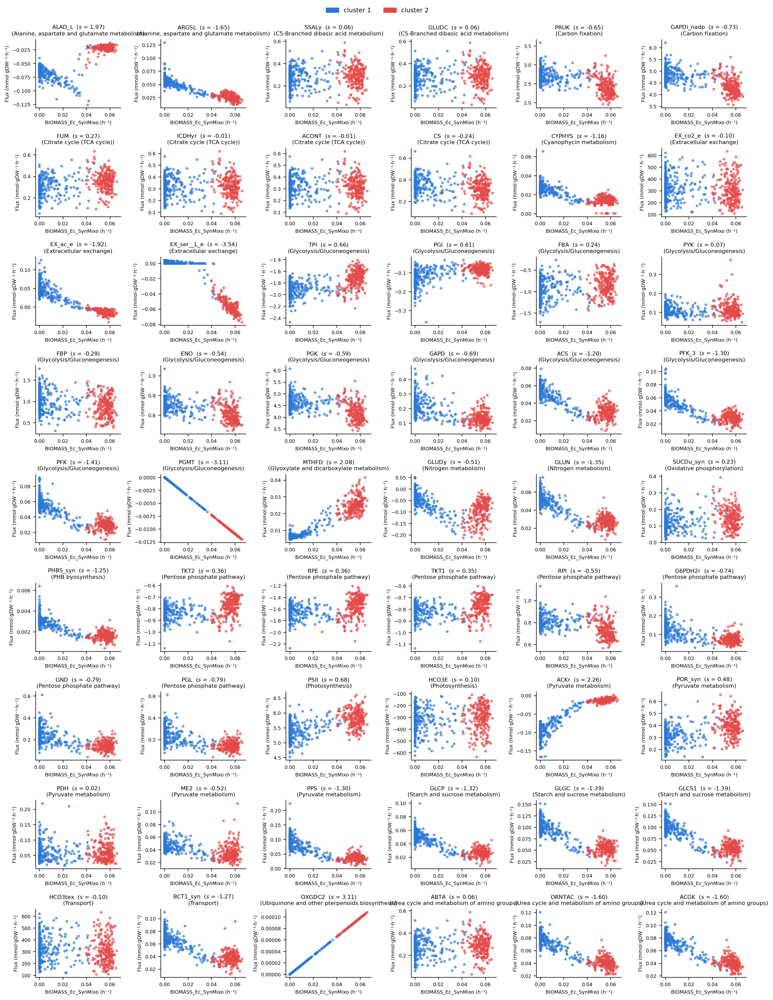

In [9]:
import matplotlib.pyplot as plt
COLOR_CLUSTER_A = "#2a78d6"
COLOR_CLUSTER_B = "#e34948"



def plot_reaction_vs_growth_by_cluster(rxn_id, ax=None):
    """Scatter of a reaction's per-cell flux against growth rate, colored by cluster."""
    if ax is None:
        _, ax = plt.subplots(figsize=(3, 2))

    x = means2[rxn_id]
    for cl, color in zip(cluster_ids, [COLOR_CLUSTER_A, COLOR_CLUSTER_B]):
        mask = (cluster_labels == cl).values
        ax.scatter( growth[mask], x[mask], s=15, color=color, alpha=0.7, edgecolor="none")

    row = cluster_comparison.loc[cluster_comparison["reaction"] == rxn_id].iloc[0]
    ax.set_ylabel("Flux (mmol·gDW⁻¹·h⁻¹)")
    ax.set_xlabel(GROWTH_RXN+' (h⁻¹)')
    ax.set_title(f"{rxn_id}\n({row['subsystem']})", fontsize=9)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    return ax


sel_ids1 = tab["reaction"].tolist()          # same order as the LaTeX table (by subsystem, then s)

plot_reactions = [
    "RBPC", "RBCh", "CYTBDu", "ATPSu", "ACCOAC", "GLUTRS", "MDH", "PGM",
    "RBK", "PTAr", "ARGSS", "MTHFC", "GHMT2r", "PPC", "GLNS",
]

sel_ids = [i for i in sel_ids1 if i not in plot_reactions]

s_lookup = tab.set_index("reaction")["s"]

n_cols = min(6, len(sel_ids))               # 6 columns keeps ~70 panels to about 12 rows
n_rows = int(np.ceil(len(sel_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.5 * n_cols, 2.2 * n_rows),
                         squeeze=False, dpi=200)
axes = axes.ravel()

for rxn_id, ax in zip(sel_ids, axes):
    plot_reaction_vs_growth_by_cluster(rxn_id, ax=ax)
    row = cluster_comparison.loc[cluster_comparison["reaction"] == rxn_id].iloc[0]
    ax.set_title(f"{rxn_id}  ($s$ = {s_lookup[rxn_id]:.2f})\n({row['subsystem']})", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.xaxis.label.set_size(7)
    ax.yaxis.label.set_size(7)

for ax in axes[len(sel_ids):]:
    ax.axis("off")

fig.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_A, label=f"cluster {cl_a+1}"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_B, label=f"cluster {cl_b+1}"),
    ],
    loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.005), fontsize=9,
)
plt.tight_layout(rect=(0, 0, 1, 0.99))

fig.savefig(os.path.join(CLUSTER_COMPARISON_DIR, "selected_reactions_vs_growth.pdf"),
            bbox_inches="tight")
plt.show()

In [10]:
317/520

0.6096153846153847

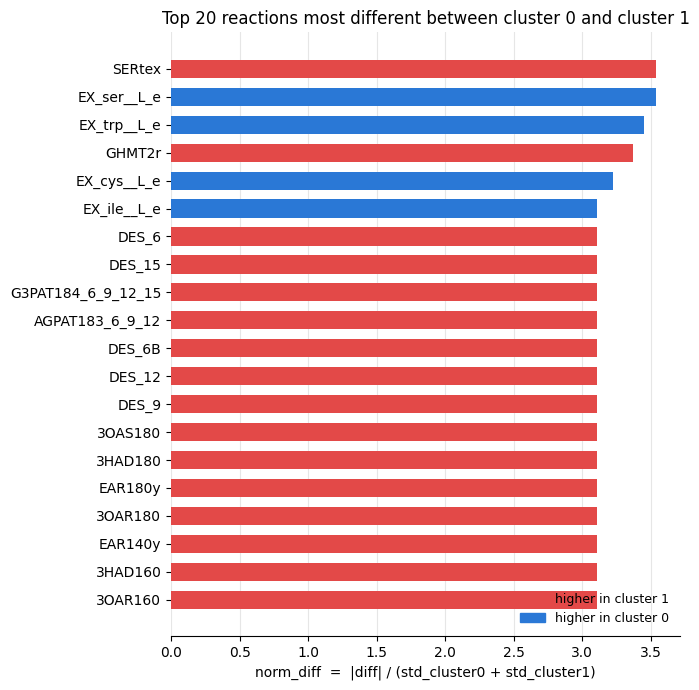

In [11]:
import matplotlib.pyplot as plt

TOP_N_PLOT = 20  # <-- EDIT: how many top-ranked reactions to show in the bar chart

# blue / red diverging pair -- which cluster has the higher average flux
COLOR_CLUSTER_A = "#2a78d6"
COLOR_CLUSTER_B = "#e34948"

top_plot = rank_filtered.head(TOP_N_PLOT).iloc[::-1]  # reverse so rank #1 ends up on top
bar_colors = np.where(top_plot["diff"] > 0, COLOR_CLUSTER_B, COLOR_CLUSTER_A)

fig, ax = plt.subplots(figsize=(7, max(3, 0.35 * len(top_plot))))
ax.barh(top_plot["reaction"], top_plot["norm_diff"], color=bar_colors, height=0.65)
ax.set_xlabel(f"norm_diff  =  |diff| / (std_cluster{cl_a} + std_cluster{cl_b})")
ax.set_title(f"Top {len(top_plot)} reactions most different between cluster {cl_a} and cluster {cl_b}")
ax.grid(axis="x", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_B, label=f"higher in cluster {cl_b}"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_A, label=f"higher in cluster {cl_a}"),
    ],
    loc="lower right", frameon=False, fontsize=9,
)

plt.tight_layout()
plt.show()

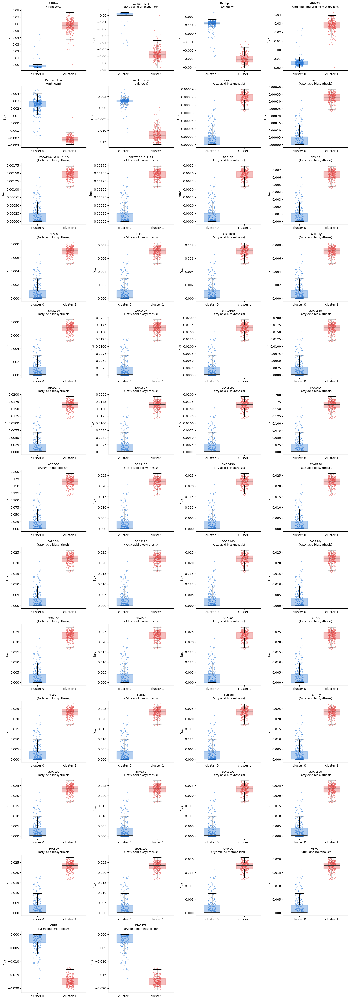

In [12]:
def plot_reaction_by_cluster(rxn_id, ax=None):
    """Boxplot + individual cells (jittered) of a reaction's per-cell flux, split by cluster."""
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3.5))

    data = [means2.loc[cluster_labels.index[cluster_labels == cl], rxn_id].values for cl in cluster_ids]
    box_colors = [COLOR_CLUSTER_A, COLOR_CLUSTER_B]

    bp = ax.boxplot(data, positions=range(len(cluster_ids)), widths=0.5, patch_artist=True, showfliers=False)
    for patch, color in zip(bp["boxes"], box_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.35)
        patch.set_edgecolor(color)
    for median in bp["medians"]:
        median.set_color("0.2")

    rng = np.random.default_rng(0)
    for i, vals in enumerate(data):
        jitter = rng.uniform(-0.12, 0.12, size=len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, s=8, color=box_colors[i], alpha=0.6, edgecolor="none")

    ax.set_xticks(range(len(cluster_ids)))
    ax.set_xticklabels([f"cluster {cl}" for cl in cluster_ids])
    row = cluster_comparison.loc[cluster_comparison["reaction"] == rxn_id].iloc[0]
    ax.set_title(f"{rxn_id}\n({row['subsystem']})", fontsize=9)
    ax.set_ylabel("flux")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    return ax


TOP_N_DETAIL = 50  # <-- EDIT: how many top reactions to show as individual box/strip plots

top_ids = rank_filtered.head(TOP_N_DETAIL)["reaction"].tolist()
n_cols = min(4, len(top_ids))
n_rows = int(np.ceil(len(top_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows), squeeze=False)
axes = axes.ravel()
for rxn_id, ax in zip(top_ids, axes):
    plot_reaction_by_cluster(rxn_id, ax=ax)
for ax in axes[len(top_ids):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [20]:
RANK_METRIC = "mean_norm_diff"  # <-- EDIT: "mean_norm_diff" (avg per-reaction shift) or "sum_norm_diff" (whole-pathway footprint)

subsystem_diff = (
    rank_filtered  # already restricted to reactions above POP_AVG_MIN
    .groupby("subsystem")
    .agg(
        n_reactions=("reaction", "count"),
        mean_norm_diff=("norm_diff", "mean"),
        sum_norm_diff=("norm_diff", "sum"),
        mean_diff=("diff", "mean"),
        n_higher_in_cluster_b=("diff", lambda s: (s > 0).sum()),
        n_higher_in_cluster_a=("diff", lambda s: (s < 0).sum()),
    )
    .sort_values(RANK_METRIC, ascending=False)
    .reset_index()
)

sub_path = os.path.join(CLUSTER_COMPARISON_DIR, "subsystem_rank_cluster_difference.csv")
#subsystem_diff.columns = ['subsystem', 'n_reactions', r'$\bar{s}$', r'$\sum s$', r'$\bar{\Delta}$', 'n_higher_in_cluster1', 'n_higher_in_cluster2']
subsystem_diff.to_csv(sub_path, index=False)
print(f"Saved subsystem-level ranking -> {sub_path}")
subsystem_diff.head(50)

Saved subsystem-level ranking -> cluster_comparison/subsystem_rank_cluster_difference.csv


,subsystem,n_reactions,mean_norm_diff,sum_norm_diff,mean_diff,n_higher_in_cluster_b,n_higher_in_cluster_a
0,Biomass and maintenance functions,1,3.105425,3.105425,0.049141,1,0
1,Peptidoglycan biosynthesis,8,3.105425,24.843396,0.001240,8,0
2,Lipopolysaccharide biosynthesis,5,3.105425,15.527123,0.001984,5,0
3,Aminosugars metabolism,5,3.105424,15.527122,0.001488,4,1
4,Galactolipids metabolism,13,3.105424,40.370517,0.001027,13,0
5,Sulfolipid Biosynthesis,6,3.105424,18.632545,0.000680,6,0
6,Glutamate metabolism,5,3.088996,15.444981,0.003929,4,1
7,Carotenoid Biosynthesis,11,3.071907,33.790975,0.000395,11,0
8,Porphyrin and chlorophyll metabolism,16,3.066635,49.066159,0.002201,16,0
9,Fatty acid biosynthesis,77,3.055592,235.280551,0.009819,77,0


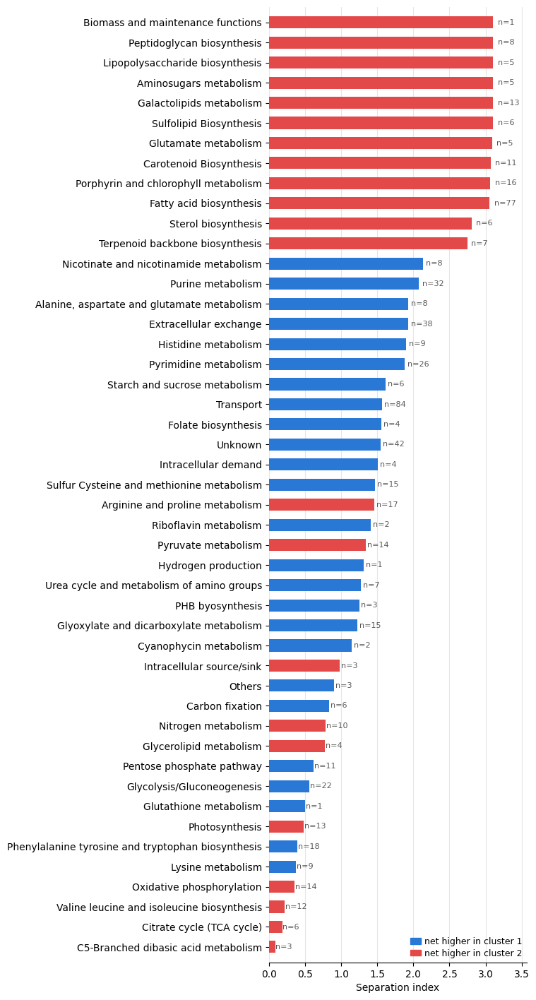

In [21]:
TOP_N_SUBSYSTEMS = 48  # <-- EDIT

top_sub = subsystem_diff.head(TOP_N_SUBSYSTEMS).iloc[::-1]

bar_colors = np.where(top_sub["mean_diff"] > 0, COLOR_CLUSTER_B, COLOR_CLUSTER_A)

fig, ax = plt.subplots(figsize=(7.5, max(3, 0.3 * len(top_sub))))
ax.barh(top_sub["subsystem"], top_sub[RANK_METRIC], color=bar_colors, height=0.6)
for y, n in zip(range(len(top_sub)), top_sub["n_reactions"]):
    ax.text(top_sub[RANK_METRIC].iloc[y] * 1.02, y, f"n={n}", va="center", fontsize=8, color="0.35")

ax.set_xlim(0, top_sub[RANK_METRIC].max() * 1.15)  # just enough room for the n= labels
ax.margins(y=0.01)  # bars flush to the top/bottom of the axes instead of the default 5% pad

ax.set_xlabel('Separation index')
#ax.set_title(f"Subsystems most different between cluster {cl_a} and cluster {cl_b}")
ax.grid(axis="x", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_A, label=f"net higher in cluster {cl_a+1}"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_B, label=f"net higher in cluster {cl_b+1}"),
      
    ],
    loc="lower right",
    frameon=False,
    fontsize=9,
    borderaxespad=0.3,
    borderpad=0.2,
    handlelength=1.2,
    handletextpad=0.4,
    labelspacing=0.3,
)

plt.tight_layout(pad=0.5)
plt.savefig('metabolic_enrichment.jpeg', format='jpeg', dpi=200, bbox_inches='tight')
plt.show()

selected = ['Biomass and maintenance functions', 'Fatty acid biosynthesis', 'Purine metabolism', 'PHB biosynthesis', 
            'Pyruvate metabolism',  'Cyanophicin metabolism', 'Glycolysis/Gluconeogenesis', 'Oxidative phosphorilation', 
            'Citrate cycle (TCA cycle)']

                        subsystem  n_reactions  mean_norm_diff  mean_diff    signed
                Purine metabolism           32        2.077917  -0.001690 -2.077917
                 PHB byosynthesis            3        1.252583  -0.001323 -1.252583
           Cyanophycin metabolism            2        1.151522  -0.011350 -1.151522
       Glycolysis/Gluconeogenesis           22        0.563334  -0.012187 -0.563334
        Citrate cycle (TCA cycle)            6        0.189369   0.014630  0.189369
        Oxidative phosphorylation           14        0.353742   0.012079  0.353742
              Pyruvate metabolism           14        1.337619   0.001442  1.337619
          Fatty acid biosynthesis           77        3.055592   0.009819  3.055592
Biomass and maintenance functions            1        3.105425   0.049141  3.105425
saved subsystem_sketch.svg and subsystem_sketch.png


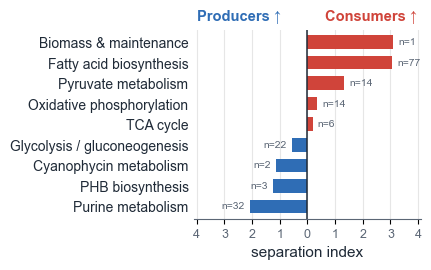

In [27]:
"""
Sketch-figure version of the subsystem separation plot, restricted to a few
selected subsystems and drawn diverging: bars to the left are net higher in
Subpop. 1 (cluster 1), bars to the right net higher in Subpop. 2 (cluster 2).

Bar length = mean separation index of the subsystem's reactions
(mean_norm_diff, |mu_b - mu_a| / (sd_a + sd_b)); side = sign of mean_diff,
exactly as the colour in the full plot from NEW_cluster_comparison.

Input: cluster_comparison/subsystem_rank_cluster_difference.csv
Run from the single_cell_metabolic_flux_analysis folder:
    python subsystem_sketch.py
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- settings ----------------
CSV = "cluster_comparison/subsystem_rank_cluster_difference.csv"
OUT = "subsystem_sketch"
RANK_METRIC = "mean_norm_diff"

# selected subsystems -> label shown in the figure
# (keys must match the model's subsystem names, including its spellings)
SELECTED = {
    "Biomass and maintenance functions": "Biomass & maintenance",
    "Fatty acid biosynthesis": "Fatty acid biosynthesis",
    "Purine metabolism": "Purine metabolism",
    "PHB byosynthesis": "PHB biosynthesis",
    "Pyruvate metabolism": "Pyruvate metabolism",
    "Cyanophycin metabolism": "Cyanophycin metabolism",
    "Glycolysis/Gluconeogenesis": "Glycolysis / gluconeogenesis",
    "Oxidative phosphorylation": "Oxidative phosphorylation",
    "Citrate cycle (TCA cycle)": "TCA cycle",
}
SHOW_N = True                       # n = number of reactions in the subsystem
COLOR_A, COLOR_B = "#2f6db5", "#d0443a"   # Subpop. 1, Subpop. 2 (same as the other panels)
INK = "#1f2a37"
MUTED = "#5b6675"
FIGSIZE = (4.2, 2.6)
# ------------------------------------------

d = pd.read_csv(CSV)
missing = [s for s in SELECTED if s not in set(d["subsystem"])]
if missing:
    print("Not found in the table (check spelling):", missing)
d = d[d["subsystem"].isin(SELECTED)].copy()
d["signed"] = np.sign(d["mean_diff"]) * d[RANK_METRIC]
d = d.sort_values("signed").reset_index(drop=True)   # most Subpop.-1 at the bottom
d["label"] = d["subsystem"].map(SELECTED)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 11, "svg.fonttype": "none", "mathtext.fontset": "dejavusans",
})
fig, ax = plt.subplots(figsize=FIGSIZE)

y = np.arange(len(d))
colors = np.where(d["signed"] > 0, COLOR_B, COLOR_A)
ax.barh(y, d["signed"], color=colors, height=0.66, zorder=2)
ax.axvline(0, color=INK, lw=1.1, zorder=3)

lim = d[RANK_METRIC].max() * 1.32
ax.set_xlim(-lim, lim)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_yticks(y)
ax.set_yticklabels(d["label"], fontsize=10, color=INK)
ax.tick_params(axis="y", length=0, pad=4)

if SHOW_N:
    for yi, (v, n) in enumerate(zip(d["signed"], d["n_reactions"])):
        ax.text(v + (0.06 if v >= 0 else -0.06) * lim / 1.32, yi, f"n={n}",
                va="center", ha="left" if v >= 0 else "right", fontsize=7.5, color=MUTED)

# side headers instead of a legend
ax.text(-lim * 0.97, len(d) - 0.1, "Producers ↑", color=COLOR_A, fontweight="bold",
        fontsize=10.5, ha="left", va="bottom")
ax.text(lim * 0.97, len(d) - 0.1, "Consumers ↑", color=COLOR_B, fontweight="bold",
        fontsize=10.5, ha="right", va="bottom")

ax.set_xlabel("separation index", color=INK, fontsize=11)
ticks = np.arange(-np.floor(lim), np.floor(lim) + 1, 1)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{abs(t):g}" for t in ticks], fontsize=9, color=MUTED)
ax.grid(axis="x", color="0.9", lw=0.8, zorder=0)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(MUTED)

fig.tight_layout(pad=0.3)
fig.savefig(f"{OUT}.svg", transparent=True, bbox_inches="tight")
fig.savefig(f"{OUT}.png", dpi=100, transparent=True, bbox_inches="tight")
print(d[["subsystem", "n_reactions", RANK_METRIC, "mean_diff", "signed"]].to_string(index=False))
print(f"saved {OUT}.svg and {OUT}.png")

/home/arianferrero/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


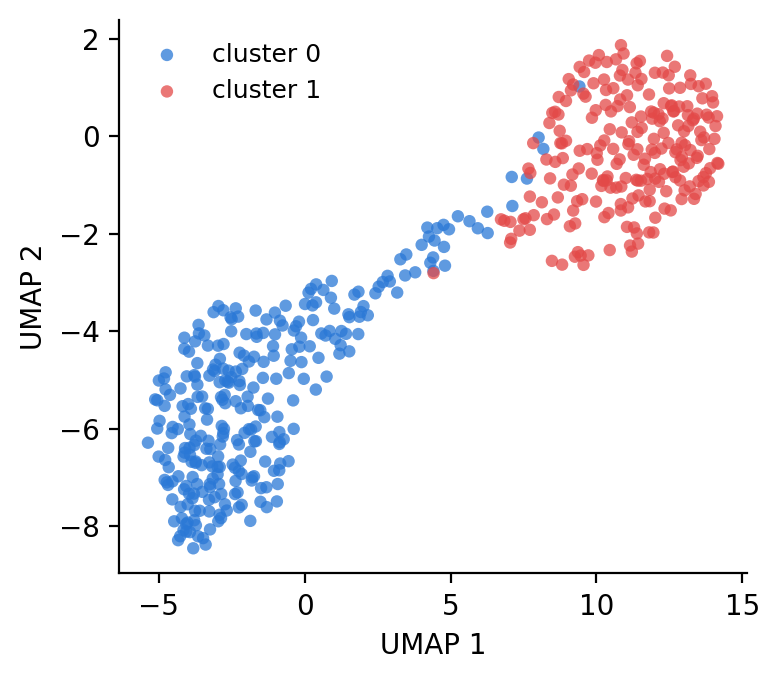

In [17]:
try:
    import umap
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "umap-learn"], check=True)
    import umap

from sklearn.preprocessing import StandardScaler

UMAP_N_NEIGHBORS = 15 # <-- EDIT: larger = more global structure, smaller = more local clusters
UMAP_MIN_DIST = 0.5     # <-- EDIT: larger = points spread out more, smaller = tighter clumps
UMAP_RANDOM_STATE = 0

X_all = means2  # full population, every sampled reaction (no variance filtering)
Xs_all = StandardScaler().fit_transform(X_all)

reducer = umap.UMAP(
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    random_state=UMAP_RANDOM_STATE,
)
embedding = reducer.fit_transform(Xs_all)

fig, ax = plt.subplots(figsize=(4, 3.5), dpi=200)
for cl, color in zip(cluster_ids, [COLOR_CLUSTER_A, COLOR_CLUSTER_B]):
    mask = (cluster_labels == cl).values
    ax.scatter(embedding[mask, 0], embedding[mask, 1], s=20, color=color, alpha=0.75,
               label=f"cluster {cl}", edgecolor="none")

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
#ax.set_title("UMAP of the full flux-sampling population, colored by cluster")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [50]:
top_per_subsystem = (
    rank_filtered
    .sort_values("norm_diff", ascending=False)
    .drop_duplicates(subset="subsystem", keep="first")  # first row per subsystem after sorting = the most different one
    .sort_values("norm_diff", ascending=False)
    .reset_index(drop=True)
)

print(f"{len(top_per_subsystem)} subsystems represented")
top_per_subsystem[["subsystem", "reaction", "name", "norm_diff", "diff"]]

47 subsystems represented


,subsystem,reaction,name,norm_diff,diff
0,Transport,SERtex,L-serine transport via diffusion (extracellula...,3.537966,0.056954
1,Extracellular exchange,EX_ser__L_e,L-Serine exchange,3.537966,-0.056954
2,Unknown,EX_trp__L_e,,3.455276,-0.004107
3,Arginine and proline metabolism,GHMT2r,"Glycine hydroxymethyltransferase, reversible",3.374971,0.041391
4,Fatty acid biosynthesis,DES_6,Stearoyl-CoA desaturase (delta-6 desaturase),3.105547,0.000104
5,Pyruvate metabolism,ACCOAC,Acetyl-CoA carboxylase,3.105426,0.144706
6,Pyrimidine metabolism,OMPDC,Orotidine-5'-phosphate decarboxylase,3.105425,0.015326
7,Folate biosynthesis,DHFR,Dihydrofolate reductase,3.105425,0.001341
8,Sulfolipid Biosynthesis,SQD2_182_9_12,Sulfoquinovosyltransferase (n-C18 2),3.105425,0.000401
9,Peptidoglycan biosynthesis,UAGPT3,UDP-N-acetylglucosamine-N-acetylmuramyl-(penta...,3.105425,0.001240


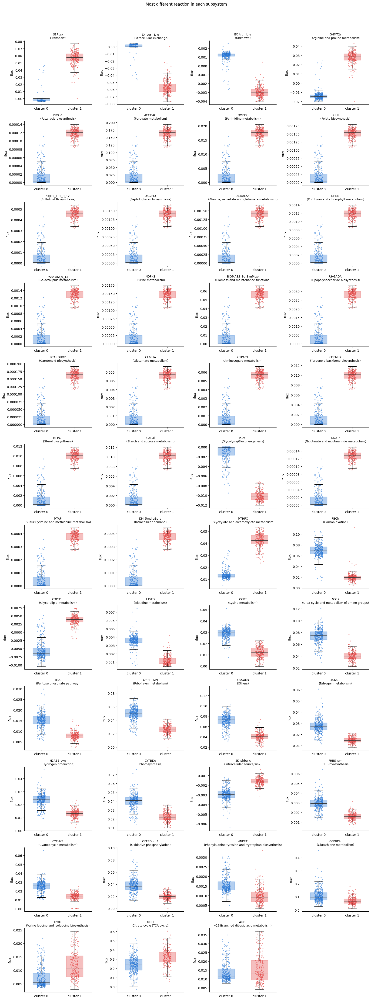

In [51]:
top_ids = top_per_subsystem["reaction"].tolist()

n_cols = min(4, len(top_ids))
n_rows = int(np.ceil(len(top_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.5 * n_rows), squeeze=False)
axes = axes.ravel()
for rxn_id, ax in zip(top_ids, axes):
    plot_reaction_by_cluster(rxn_id, ax=ax)  # the helper you already have from the per-reaction detail cell
for ax in axes[len(top_ids):]:
    ax.axis("off")

fig.suptitle("Most different reaction in each subsystem", y=1.02)
plt.tight_layout()
plt.show()

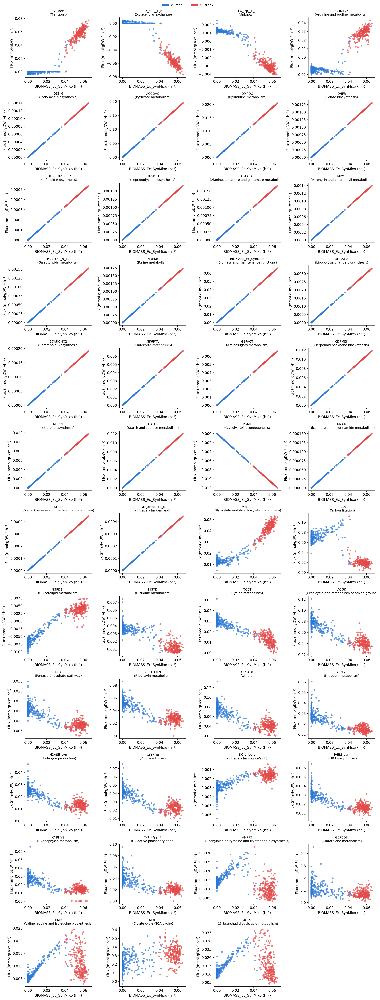

In [75]:
def plot_reaction_vs_growth_by_cluster(rxn_id, ax=None):
    """Scatter of a reaction's per-cell flux against growth rate, colored by cluster."""
    if ax is None:
        _, ax = plt.subplots(figsize=(3, 2))

    x = means2[rxn_id]
    for cl, color in zip(cluster_ids, [COLOR_CLUSTER_A, COLOR_CLUSTER_B]):
        mask = (cluster_labels == cl).values
        ax.scatter( growth[mask], x[mask], s=22, color=color, alpha=0.7, edgecolor="none")

    row = cluster_comparison.loc[cluster_comparison["reaction"] == rxn_id].iloc[0]
    ax.set_ylabel("Flux (mmol·gDW⁻¹·h⁻¹)")
    ax.set_xlabel(GROWTH_RXN+' (h⁻¹)')
    ax.set_title(f"{rxn_id}\n({row['subsystem']})", fontsize=9)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    return ax


top_ids = top_per_subsystem["reaction"].tolist()

n_cols = min(4, len(top_ids))
n_rows = int(np.ceil(len(top_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.8 * n_cols, 3.3 * n_rows), squeeze=False, dpi=200)
axes = axes.ravel()
for rxn_id, ax in zip(top_ids, axes):
    plot_reaction_vs_growth_by_cluster(rxn_id, ax=ax)
for ax in axes[len(top_ids):]:
    ax.axis("off")

fig.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_A, label=f"cluster {cl_a+1}"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_CLUSTER_B, label=f"cluster {cl_b+1}"),
    ],
    loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5,1.005), fontsize=9,
)
#fig.suptitle("Most different reaction in each subsystem, vs. growth rate", y=1.08)
plt.tight_layout()
plt.show()

## Notes / things you may want to tune

- **`POP_AVG_MIN`** filters out reactions that are essentially inactive
  across the whole population before ranking. It's applied to the
  *absolute* population-wide average flux — flip to a signed comparison
  (`cluster_comparison["population_mean"] > POP_AVG_MIN`) if you only want
  reactions with a positive population-wide average.
- **`diff` / `abs_diff`** are plain differences of per-cluster means, not a
  statistical test — a reaction can rank highly here even if the two
  clusters' sampling variance overlaps a lot; check `std_cluster{c}` /
  `n_cells_cluster{c}` alongside it if that matters for your interpretation.
- If you ever have more than two clusters, the ranking cell will raise an
  assertion — swap `diff`/`abs_diff` for a per-pair comparison or e.g. the
  max spread across `mean_cluster{c}` columns.